# A simple non-Poissonian example

In this example, we will perform a non-Poissonian template scan, including Poissonian templates for 

1. isotropic emission 
2. bubbles-correlated emission
3. diffuse-model correlated emission
4. NFW-DM correlated emission 

and non-Poissonian templates for 

1.  NFW-correlated PSs
2.  Disk-correlated PSs

We will between Fermi energy bin numbers 8 - 16.  In the process, we will see how to use different PSF models, load in templates from file, and plot source-count functions.

For this example, we assume familiarity with the example `poissonian_single_bin` and `poissonian_compute_spectrum`.

In [1]:
import sys
sys.path.append("..")

In [1]:
from global_variables import *
from global_var import *

In [2]:
import sys
sys.path.append("/group/hepheno/smsharma/NPTFit/Testing")

from NPLL import log_like

In [3]:
%load_ext autoreload
%autoreload 2

#################
###relevant modules
import copy
import numpy as np
import matplotlib.pyplot as plt
import healpy as hp

#################
###relevant modules from NPTF package
import fermi.fermi_plugin as fp  #module for loading templates needed for scan
import config.bayesian_scan_models as bsm #module for performing scan


## Define the directories and physics variables for the scan

In [4]:
work_dir = '/group/hepheno/smsharma/NPTFit/Sid_Testing'  #chains, plots, and data folders created here
maps_dir = '/mnt/hepheno/CTBCORE/'  #should contain data, unless otherwise specificed, along with other relevant data files, such as PSF fits files
psf_dir = work_dir + 'psf/' #directory where to save rho(f) files for taking into account PSF in NPTF

In [5]:
tag = 'examples'
run_tag = 'testing' 

In [6]:
CTB_en_min = 8
CTB_en_max=16
nside=128

In [7]:
band_mask_range =  [-2.,2.]  
mask_ring = True
outer=30  

In [8]:
mask_type = '0.95' 
force_energy=True 
energy_bin_mask = 8 

In [9]:
# Setup fermi details
# User options
nside=128
eventclass=5 # 2 (Source) or 5 (UltracleanVeto)
eventtype=3 # 0 (all), 3 (bestpsf) or 5 (top3 quartiles)
tag='CC_lims_phot'
mask_type='top300'
force_mask_at_bin_number=8
emin_bin=9
emax_bin=10
band_mask_val = 30

## Setup fermi_plugin

In [10]:
f = fp.fermi_plugin(maps_dir,fermi_data_dir=fermi_data_dir,work_dir=work_dir,CTB_en_min=emin_bin,CTB_en_max=emax_bin,nside=nside,eventclass=eventclass,eventtype=eventtype,newstyle=1)

In [11]:
f.add_diffuse_newstyle(comp = 'p6', eventclass =f.eventclass, eventtype = f.eventtype)
f.add_bubbles() #bubbles
f.add_iso()  #iso
f.add_nfw()  #NFW-DM
# f.add_template_from_file('disk',disk_file_name) #we will call template 'disk'

Just loading NFW intensity map ...


In [12]:
f.make_ps_mask(mask_type = mask_type,energy_bin = energy_bin_mask,force_energy=force_energy)

Taking PS mask from energy 1.89287203344


Now, we want to use a template normalization file.  We will use the one we created in a previous example. The `key_suffix` is what was appended to the template keys---namely, the energy-bin label `-0`

In [13]:
# f.use_template_normalization_file(work_dir+'data/spect/test_normalization_example.npy',key_suffix='-0')

## Now we will make an instance of bayesian_scan_models to setup the template scan

### Setting up the scan

In [14]:
b = bsm.bayesian_scan_NPTF(tag=tag,nside=nside,work_dir=work_dir,psf_dir=psf_dir)
b.load_external_data(f.CTB_en_bins,f.CTB_count_maps,f.CTB_exposure_maps)
b.make_mask_total(band_mask_range =  band_mask_range,mask_ring = mask_ring,outer=outer,ps_mask_array = f.ps_mask_array)

In [15]:
b.add_new_template(f.template_dict)
b.rebin_external_data(1)

Now let's add our Poissonian models

In [16]:
b.add_poiss_model('nfw','$A_{nfw}$',[-6,6],True)
b.add_poiss_model('p6','$A_{p6}$',[0,2],False)
b.add_poiss_model('bubs','$A_{bubs}$',[0,2],False)
b.add_poiss_model('iso','$A_{iso}$',[-2,2],False)

Now let's add our non-Poissonian models.  There are 4 arguments to `add_non_poiss_model`:
1.  keyword for template
2.  An array of tags for the template, used to label plots
3.  The prior range array
4.  An array of whether or not the prior is log-flat( `True` equals log-flat)

The source-count function parameters are given by [$\tilde A$, $n_1$, $n_2$, $S_b$].  The source-count function, in terms of these paramters, is 

$${dN^{(p)} \over dS} = A \, T^p \left\{ \begin{array}{cc} 
\left( {S \over S_b} \right)^{-n1} & S_c > S > S_b  \\ 
\left( {S \over S_b} \right)^{-n2} & S < S_b   \end{array} \right.$$

By default, $S_c$ is set to a very large number (this can be changed if desired).  Here, $A$ and $\tilde A$ are related by 

$$ A = {\tilde A \over S_b}$$

This is done so that the number of PSs does not depend on the break, $S_b$.  The template $T^{p}$ ($p$ is a pixel index) is the spatial template for the PS component.  By default, this is set to the sum, over all energy bins in the scan, of the relevant PS template.  See the class `config.bayesian_scan_models.bayesian_scan_NPTF` for more info and options.

In [17]:
b.add_non_poiss_model('nfw',['$\\tilde A_{ps}$','$n_1$','$n_2$','$S_b^{(1)}$'],[[-6,6],[2.05,30],[-2,1.95],[0.05,30]],[True,False,False,False])
b.add_non_poiss_model('iso',['$\\tilde A_{disk}$','$n_1^{d}$','$n_2^{d}$','$S_{b,(d)}^{(1)}$'],[[-6,6],[2.05,30],[-2,1.95],[0.05,30]],[True,False,False,False])

Now, we need to load in some info to take into account the PSF when doing the NPTF.  I will illustrate first how to use a Gaussian PSF, and then how to use the Kings function.  Anticipating step 2, I will start by copying the current object `b`.

In [18]:
b_kings = copy.deepcopy(b)

Now, we need to compute `\sigma` (for the 2-d Gaussian, averaged over energy).  We compute a dictionary for this, where we use the spectrum of each template to do the average.

In [19]:
f.load_psf()

Here is what that dictionary looks like

In [20]:
print f.average_PSF_dict

{'nfw': 0.13204506414284142, 'p6': 0.13204506414284142, 'iso': 0.13204506414284142, 'bubs': 0.13204506414284142}


We will use `nfw`

In [21]:
sigma_PSF_deg = f.average_PSF_dict['nfw']

Now, we will initiate the NPTF.  We have 2 PS templates, so we use `b.initiate_2_ps_edep`.  There are also functions for initializing 1 PS and 3 PS.

In [22]:
b.initiate_ps_from_f_ary(f.f_ary_list, f.df_rho_div_f_ary_list, nbreak=1)

config/config_file.py:370: VisibleDeprecationWarning: using a non-integer number instead of an integer will result in an error in the future
  new_data_masked[mask_array[i]] = 1


$A_{nfw}$
$A_{iso}$
$A_{p6}$
$A_{bubs}$
0 [True, False, False, False]
1 [True, False, False, False]
2 [True, False, False, False]
3 [True, False, False, False]
0 [True, False, False, False]
1 [True, False, False, False]
2 [True, False, False, False]
3 [True, False, False, False]
The k_max_array is  [27.0]
The number of parameters is  12


### Running the scan

At this point, the syntax to run a scan is just like that for the Poissonian scans.  This might take about ~30 minutes.  Go get a coffee.  If it takes significantly longer than half and hour, you may have a problem / your computer is slower than mine.

In [23]:
reload(bsm)

<module 'config.bayesian_scan_models' from 'config/bayesian_scan_models.pyc'>

In [ ]:
b.perform_scan(run_tag=run_tag)

/group/hepheno/smsharma/NPTFit/Sid_Testingchains/CC_lims_phot/testing/


## Analysis

### Triange plots and intensities/spectrum

First, let's take a look at the triangle plot.  

In [27]:
mt=fa.make_triangle(b,run_tag,edep=True)
mt.make_triangle(return_fig=True,save_fig=False)

NameError: name 'fa' is not defined

Not all priors are very well converged.  In retrospect, maybe we should have made some of these prior ranges wider (such as the break for the disk)

We can also compute the spectrum/intensity

In [74]:
outer_plot=10 #this is the outer radius for the spectrum analysis
kwargs_spectrum={ 'band_mask_range': band_mask_range,'mask_ring': mask_ring, 'outer': outer_plot}

In [120]:
cs=fa.compute_edep_spectra(b,run_tag,b.CTB_en_bins,**kwargs_spectrum)

In load_scan: polychord, minuit: False False
  analysing data from /Users/bsafdi/Dropbox/Edep-NPTF/github/NPTF/chains/examples/IG_NPTF_en_8_16/.txt
the medians are  [-3.59543038905966, 1.0345930987589917, 0.9811066078933829, 1.0047251381083688, -0.6382250824119117, 18.70057723254477, -1.0498998206188852, 12.783559869025941, -3.2069846555582995, 10.839813037847579, -0.8083030587496873, 25.818787987852193]
the medians (from chains) are  [ -3.60656026   1.03592786   0.9809875    1.00393377  -0.63575421
  18.45832708  -1.07545686  12.78049142  -3.20327835  10.94065213
  -0.79833284  25.80111977]
the number of parameters is  12
self.poiss_comp_numbers:  {'nfw-0': 0, 'p6-0': 2, 'iso-0': 1, 'bubs-0': 3}
In load_scan: polychord, minuit: False False
  analysing data from /Users/bsafdi/Dropbox/Edep-NPTF/github/NPTF/chains/examples/IG_NPTF_en_8_16/.txt
the medians are  [-3.59543038905966, 1.0345930987589917, 0.9811066078933829, 1.0047251381083688, -0.6382250824119117, 18.70057723254477, -1.049899

And here are some intensities (photons / cm$^2$/s/sr).  Second entry is energy bin number (we only have 1 energy bin, so this is zero).

In [124]:
print 'nfw PS: ', cs.return_intensity_arrays_non_poiss('nfw',0)
print 'disk PS: ', cs.return_intensity_arrays_non_poiss('disk',0)

nfw PS:  [  4.63767929e-07   5.22562643e-07   5.89325038e-07]
disk PS:  [  4.79167725e-08   7.35410288e-08   1.01872770e-07]


Non-Poissonian intensities are calculated from `cs.cs_array[0]`.  The 0 has same meaning as above.

In [127]:
print 'p6: ',cs.cs_array[0].return_poiss_intensity_conf_int('p6-0',quant = [0.16,0.5,0.84])
print 'bubs: ',cs.cs_array[0].return_poiss_intensity_conf_int('bubs-0',quant = [0.16,0.5,0.84])
print 'nfw: ',cs.cs_array[0].return_poiss_intensity_conf_int('nfw-0',quant = [0.16,0.5,0.84])

p6:  at comp  p6-0 log prior:  False intensity:  [  5.55719115e-06   5.59905669e-06   5.63870176e-06]
[  5.55719115e-06   5.59905669e-06   5.63870176e-06]
bubs:  at comp  bubs-0 log prior:  False intensity:  [  1.87643564e-07   1.98534226e-07   2.10116064e-07]
[  1.87643564e-07   1.98534226e-07   2.10116064e-07]
nfw:  at comp  nfw-0 log prior:  True intensity:  [  2.68134697e-12   1.06220929e-10   3.75528475e-09]
[  2.68134697e-12   1.06220929e-10   3.75528475e-09]


### PS-specific analyses: source-count function

#### 1.  The 3FGL sources

First, let's take a look at the 3FGL sources.  Set `only_gal=True` to only look at PSs that aren't explicitly known to be extra-galactic

In [103]:
only_gal=True
flux_min=1e-11 #photons/cm^2/s/sr
flux_max=1e-8
n_flux_bins=15
error_range=0.68 #for plotting uncertanties

Note that we use the same mask kwargs that we use previously

In [104]:
p3FGL = fa.plot_3FGL(f,only_gal=False,CTB_en_min=b.CTB_en_min,CTB_en_max=b.CTB_en_max,**kwargs_spectrum)

8 16
0 8


In [105]:
p3FGL.configure_3FGL(flux_min=flux_min,flux_max=flux_max,n_flux_bins = n_flux_bins,error_range = error_range)   

`plot_3FGL` accepts all `args` and `kwargs` that `plt.errorbar` does.

#### 2.  The best-fit dN/dS

In [93]:
pdnds = fa.plot_dnds(b,**kwargs_spectrum) #again, same kwargs

The following functions take `*args` and `**kwargs` for `plt.plot` and `plt.fill_between`, respectively.  We will use `nsteps` photon-count bins between `smax` and `smin`.

#### 3.  Plot $dN / dF$

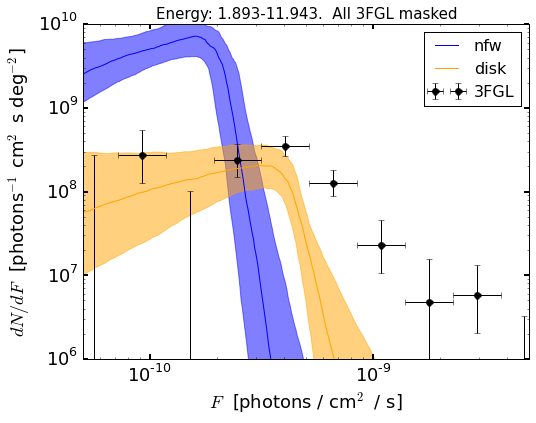

In [116]:
plt.figure(figsize=(8,6))
#plot medians
pdnds.plot_source_count_median('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='blue',label='nfw')
pdnds.plot_source_count_median('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='orange',label='disk')

#plot band
pdnds.plot_source_count_band('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='blue',label='nfw',alpha=0.5)
pdnds.plot_source_count_band('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='orange',label='disk',alpha=0.5)

#also show 3FGL
p3FGL.plot_3FGL(fmt = 'o', color='black',markersize=7,label='3FGL')

plt.legend(fontsize=16) 

plt.yscale('log')
plt.xscale('log')
plt.xlim([5e-11,5e-9])
plt.ylim([1e6,1e10])

plt.tick_params(axis='x', length=5,width=2,labelsize=18)
plt.tick_params(axis='y',length=5,width=2,labelsize=18)
plt.xlabel('$F$  [photons / cm$^2$ / s]', fontsize=18)
plt.ylabel('$dN/dF$  [photons$^{-1}$ cm$^2$ s deg$^{-2}$]', fontsize=18)

plt.title('Energy: '+str(np.round(b.CTB_en_bins[0],3)) + '-'+str(np.round(b.CTB_en_bins[0+1],3))+ '.  All 3FGL masked',fontsize=15)

In [33]:
len(b.non_poiss_models)

1

## Using a Kings PSF

### The Kings PSF

Now, we will perform the scan usings a Kings PSF

In [20]:
f.load_psf_kings()

All input energies must be in GeV


The PSF files (f and $\rho$ arrays) will be saved.  They will have the `save_tag` in the name.  We can choose this.  We will average using spectrum for `nfw`.

In [21]:
save_tag='example_psf'
f.make_f_ary_kings('iso',energy_averaged=True,psf_dir = psf_dir,psf_save_tag=save_tag )

The save_tag is  example_psf
just loading PSF ...


Here is what we have made, and how it compares to the Gaussian PSF:

In [26]:
f_ary_gauss = b.NPTF_inst_array[0].f_ary
df_rho_div_f_ary_gauss = b.NPTF_inst_array[0].df_rho_div_f_ary

In [28]:
%matplotlib inline

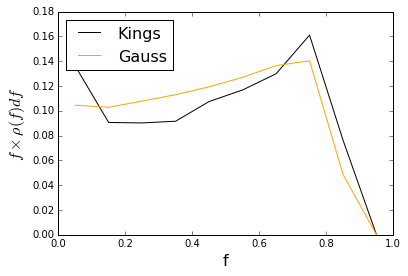

In [29]:
plt.plot(f.f_ary_list[0],f.f_ary_list[0]**2*f.df_rho_div_f_ary_list[0],label='Kings',color='black')
plt.plot(f_ary_gauss,f_ary_gauss**2*df_rho_div_f_ary_gauss,label='Gauss',color='orange')

plt.xlabel('f',fontsize=16)
plt.ylabel('$f \\times \\rho(f) df $',fontsize=16)
plt.legend(fontsize=16,loc=2)

Check normalizations:

In [151]:
print np.sum(f.f_ary_list[0]**2*f.df_rho_div_f_ary_list[0])
print np.sum(f_ary_gauss**2*df_rho_div_f_ary_gauss)

1.0
1.0


Now, when we initiate_2_ps, we input by hand the files `f_ary` and `df_rho_div_f_ary`.

In [130]:
b_kings.initiate_2_ps_edep_new_from_f_ary(f.f_ary_list,f.df_rho_div_f_ary_list)

$A_{nfw}$
$A_{p6}$
$A_{iso}$
$A_{bubs}$
The k_max_array is  [81.0]
The number of parameters is  12


### Perform the scan

This took me about 25 minutes

In [152]:
run_tag_Kings=run_tag + '-K'
b_kings.perform_scan(run_tag=run_tag_Kings)

### Analysis

Let's compare results with Kings vs. with Gaussian

In [156]:
b_kings.load_scan(run_tag=run_tag_Kings)

In load_scan: polychord, minuit: False False
  analysing data from /Users/bsafdi/Dropbox/Edep-NPTF/github/NPTF/chains/examples/IG_NPTF_en_8_16-K/.txt
the medians are  [-3.6871472463525814, 0.9838063754107791, 1.062665864886244, 0.9985693719742949, -0.37260901802973306, 19.108293298107146, -1.2041785270516765, 7.61259431905269, -3.4375353715547172, 15.64410344527689, -0.3697231851877717, 22.659113065270756]
the medians (from chains) are  [ -3.69504702   0.98374879   1.06126845   1.0001938   -0.36710589
  19.01732438  -1.20407217   7.61339872  -3.43030369  15.53361329
  -0.40498347  22.5516683 ]
the number of parameters is  12
self.poiss_comp_numbers:  {'nfw-0': 0, 'bubs-0': 3, 'iso-0': 2, 'p6-0': 1}


In [157]:
pdnds_kings = fa.plot_dnds(b_kings,**kwargs_spectrum) #again, same kwargs

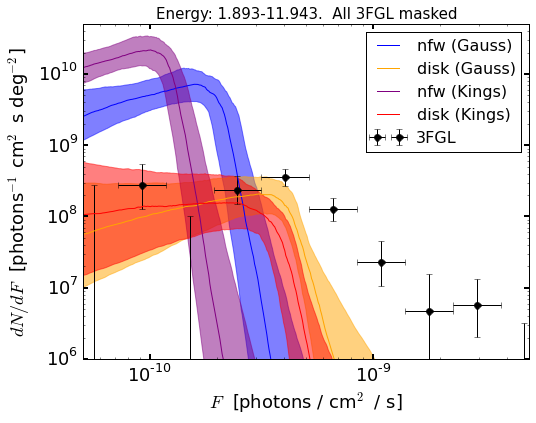

In [159]:
plt.figure(figsize=(8,6))
#plot medians
pdnds.plot_source_count_median('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='blue',label='nfw (Gauss)')
pdnds.plot_source_count_median('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='orange',label='disk (Gauss)')
pdnds_kings.plot_source_count_median('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='purple',label='nfw (Kings)')
pdnds_kings.plot_source_count_median('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,color='red',label='disk (Kings)')

#plot band
pdnds.plot_source_count_band('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='blue',label='nfw',alpha=0.5)
pdnds.plot_source_count_band('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='orange',label='disk',alpha=0.5)
pdnds_kings.plot_source_count_band('nfw',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='purple',label='nfw',alpha=0.5)
pdnds_kings.plot_source_count_band('disk',smin=0.01,smax=1000,nsteps=1000,calculate_dnds=True,edep=True,ebin=0,qs=[0.16,0.5,0.84],color='red',label='disk',alpha=0.5)

#also show 3FGL
p3FGL.plot_3FGL(fmt = 'o', color='black',markersize=7,label='3FGL')

plt.legend(fontsize=16) 

plt.yscale('log')
plt.xscale('log')
plt.xlim([5e-11,5e-9])
plt.ylim([1e6,5e10])

plt.tick_params(axis='x', length=5,width=2,labelsize=18)
plt.tick_params(axis='y',length=5,width=2,labelsize=18)
plt.xlabel('$F$  [photons / cm$^2$ / s]', fontsize=18)
plt.ylabel('$dN/dF$  [photons$^{-1}$ cm$^2$ s deg$^{-2}$]', fontsize=18)

plt.title('Energy: '+str(np.round(b.CTB_en_bins[0],3)) + '-'+str(np.round(b.CTB_en_bins[0+1],3))+ '.  All 3FGL masked',fontsize=15)

With the Kings, the source-count functions seem to get pushed to lower flux.  There may still be bugs.  Stick to Gaussian for now.